# E207 · Decoupled DINO teacher timescales

Can a passive EMA observer improve the model we deploy while the reference teacher keeps training the student?

Three paired E205 seeds follow their archived 672-minibatch streams. Every observer starts from the same teacher and averages the same student after each update. The 1× readout uses the actual reference teacher, verified against the equivalent passive update. The other rates are 0.25×, 2× and 4× of the scheduled teacher replacement rate, with the E205 momentum clamp.

## Progress

**Phase B complete · passive and feedback results saved** · updated 2026-11-21T14:54:31.044866+01:00.

Phase A **3/3** trajectories. Phase B **12/12** branches.

## What the two phases test

- **A · Passive readout.** Score scene kNN, five linear probes, and the fixed unlabeled audit bank for LiDAR, effective rank, normalized dispersion, retrieval margin, and CKA drift. Historical retention compares prior regimes with their most recent exit. Time averages integrate the whole readout trajectory.
- **B · Feedback.** At updates 96 and 192 on each of the three seeds, fork the reference learner. One fork keeps reference training targets, and one uses fast targets for 32 updates. Each maintains a fresh, identically initialized 4× observer. Both use reference training targets for another 32 updates with the same arrivals and augmentation draws. Read students and observers at +16, +32 and +64. The reference teacher provides the third readout on the reference-training trajectory.

Phase B opens if the 4× observer's mean endpoint scene kNN is at least 0.5 percentage points above reference and improves on both additional seeds, 5 and 6. All five linear outcomes remain visible. Phase C uses the paired results to decide whether a fixed observer suffices or a label-free selection study is warranted.

## Passive paired effects versus the reference teacher (pp)

| Observer | Probe | Endpoint | Time average | Seed 4 | Seed 5 | Seed 6 |
| --- | --- | --- | --- | --- | --- | --- |
| Slow 0.25× | scene kNN | -1.146 | -0.471 | -1.499 | -0.290 | -1.649 |
| Slow 0.25× | mean linear | -0.166 | -0.259 | -0.290 | +0.140 | -0.347 |
| Slow 0.25× | scene linear | -1.031 | -1.132 | -1.601 | -0.504 | -0.987 |
| Slow 0.25× | weather linear | +0.408 | +0.116 | +0.029 | +1.193 | +0.000 |
| Slow 0.25× | lighting linear | -0.423 | -0.258 | +0.012 | -0.882 | -0.398 |
| Slow 0.25× | traffic light linear | -0.466 | -0.698 | -1.315 | +0.068 | -0.150 |
| Slow 0.25× | pedestrian linear | +0.684 | +0.674 | +1.426 | +0.826 | -0.200 |
| Reference 1× | scene kNN | +0.000 | +0.000 | +0.000 | +0.000 | +0.000 |
| Reference 1× | mean linear | +0.000 | +0.000 | +0.000 | +0.000 | +0.000 |
| Reference 1× | scene linear | +0.000 | +0.000 | +0.000 | +0.000 | +0.000 |
| Reference 1× | weather linear | +0.000 | +0.000 | +0.000 | +0.000 | +0.000 |
| Reference 1× | lighting linear | +0.000 | +0.000 | +0.000 | +0.000 | +0.000 |
| Reference 1× | traffic light linear | +0.000 | +0.000 | +0.000 | +0.000 | +0.000 |
| Reference 1× | pedestrian linear | +0.000 | +0.000 | +0.000 | +0.000 | +0.000 |
| Medium fast 2× | scene kNN | +1.152 | +0.757 | +1.310 | +1.565 | +0.581 |
| Medium fast 2× | mean linear | +0.205 | -0.090 | +0.245 | +0.159 | +0.210 |
| Medium fast 2× | scene linear | +0.666 | +0.402 | +2.025 | +1.138 | -1.166 |
| Medium fast 2× | weather linear | +0.614 | +0.105 | -0.071 | +1.241 | +0.673 |
| Medium fast 2× | lighting linear | +0.202 | +0.116 | -0.135 | -0.156 | +0.896 |
| Medium fast 2× | traffic light linear | -0.228 | -0.476 | -0.570 | -1.042 | +0.928 |
| Medium fast 2× | pedestrian linear | -0.231 | -0.597 | -0.026 | -0.387 | -0.281 |
| Fast 4× | scene kNN | +1.732 | +1.147 | +2.405 | +1.779 | +1.011 |
| Fast 4× | mean linear | +0.549 | +0.140 | +0.549 | +0.508 | +0.591 |
| Fast 4× | scene linear | +0.446 | +0.193 | +0.846 | +0.451 | +0.041 |
| Fast 4× | weather linear | +0.212 | +0.004 | -0.449 | +0.501 | +0.585 |
| Fast 4× | lighting linear | +0.460 | +0.445 | +0.434 | +0.498 | +0.448 |
| Fast 4× | traffic light linear | +1.403 | +0.291 | +1.100 | +1.572 | +1.537 |
| Fast 4× | pedestrian linear | +0.226 | -0.233 | +0.813 | -0.481 | +0.345 |

**Feedback gate** passed. Exact E205 endpoint student parity by seed: {'4': True, '5': True, '6': True}.

### Which timescale won at each readout?

| Metric | Slow 0.25× | Reference 1× | Medium fast 2× | Fast 4× | Tied readouts |
| --- | --- | --- | --- | --- | --- |
| scene kNN | 0 | 1 | 8 | 48 | 0 |
| mean linear | 1 | 13 | 7 | 36 | 0 |

Counts are descriptive across seed–readout pairs. Repeated readouts from a seed share a trajectory.

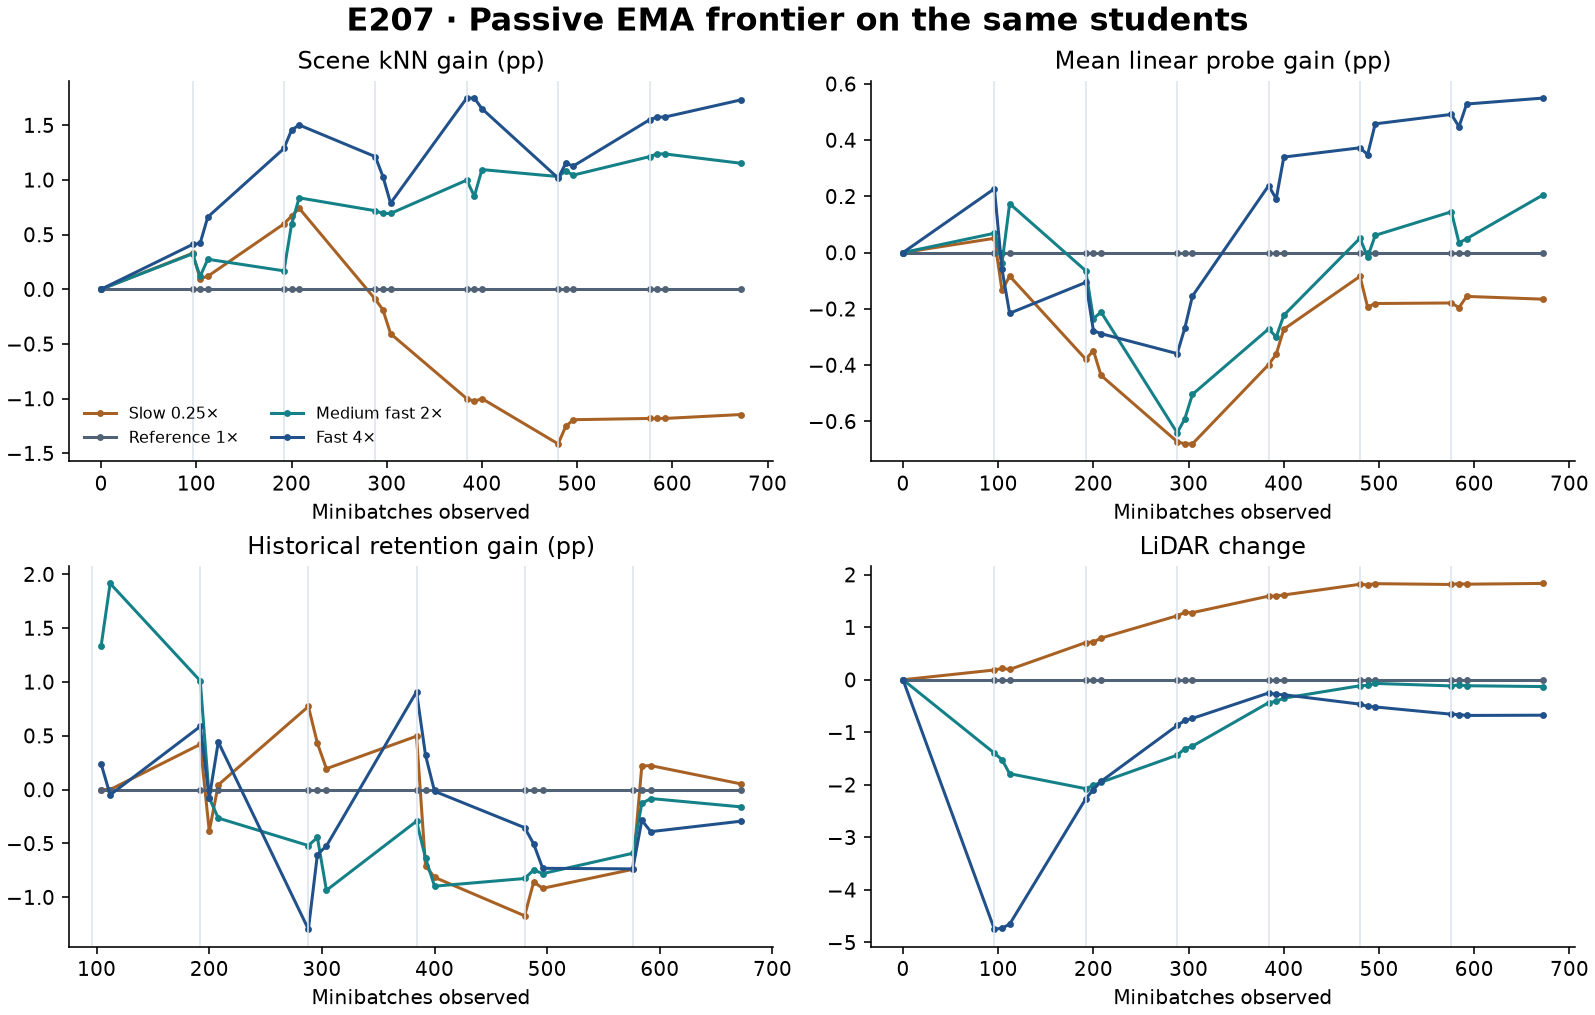

## Paired feedback comparisons (pp)

| Updates | Contrast | Scene kNN | Mean linear | Scene | Weather | Lighting | Traffic light | Pedestrian |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 16 | teaching_observer | +0.000 | -0.019 | -0.050 | -0.004 | +0.190 | -0.143 | -0.087 |
| 16 | teaching_student | +0.129 | +0.038 | +0.026 | +0.079 | +0.129 | -0.048 | +0.004 |
| 16 | passive_observer | +0.366 | +0.173 | +0.354 | +0.238 | +0.072 | +0.393 | -0.191 |
| 32 | teaching_observer | +0.061 | -0.019 | +0.042 | +0.042 | -0.129 | -0.033 | -0.018 |
| 32 | teaching_student | +0.170 | +0.120 | +0.287 | +0.058 | +0.054 | +0.008 | +0.194 |
| 32 | passive_observer | +0.604 | +0.042 | +0.337 | -0.216 | +0.411 | -0.107 | -0.218 |
| 64 | teaching_observer | +0.012 | +0.080 | +0.226 | -0.000 | +0.190 | -0.003 | -0.013 |
| 64 | teaching_student | +0.377 | +0.084 | -0.336 | +0.087 | +0.258 | +0.161 | +0.251 |
| 64 | passive_observer | +0.822 | -0.277 | +0.297 | -0.753 | +0.107 | -0.841 | -0.196 |

Teaching observer compares the two identically updated fast observers. Teaching student compares their students. Passive observer compares the fast observer and reference teacher on the reference-training trajectory.